In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA = PROJECT_ROOT / "data"
FIG = PROJECT_ROOT / "figures"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS = PROJECT_ROOT / "results"
for p in [FIG, MODEL_DIR, RESULTS]:
    p.mkdir(exist_ok=True)




In [13]:
TRAIN_FILE = DATA / "UNSW_NB15_training-set.csv"
TEST_FILE = DATA / "UNSW_NB15_testing-set.csv"

if not TRAIN_FILE.exists() or not TEST_FILE.exists():
    raise FileNotFoundError(
        "Missing dataset. Download the two CSV files and place them in the data/ folder."
    )

train = pd.read_csv(TRAIN_FILE)
test = pd.read_csv(TEST_FILE)

train.columns = [c.strip() for c in train.columns]
test.columns = [c.strip() for c in test.columns]

print("Training shape:", train.shape)
print("Testing shape :", test.shape)
display(train.head())


Training shape: (175341, 45)
Testing shape : (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


 Data quality checks and preprocessing

In [14]:
print("Training info:")
display(train.info())

print("\nMissing values (top):")
display(train.isna().sum().sort_values(ascending=False).head(15))

print("\nDuplicate rows:", train.duplicated().sum())

print("\nTarget distribution:")
display(train["label"].value_counts().rename(index={0:"Normal",1:"Attack"}))


Training info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  

None


Missing values (top):


id         0
dur        0
proto      0
service    0
state      0
spkts      0
dpkts      0
sbytes     0
dbytes     0
rate       0
sttl       0
dttl       0
sload      0
dload      0
sloss      0
dtype: int64


Duplicate rows: 0

Target distribution:


label
Attack    119341
Normal     56000
Name: count, dtype: int64

In [15]:
# Remove duplicate rows.
train = train.drop_duplicates().copy()
test = test.drop_duplicates().copy()

# Binary target.
TARGET = "label"
X_train = train.drop(columns=[TARGET, "attack_cat"], errors="ignore")
y_train = train[TARGET].astype(int)

X_test = test.drop(columns=[TARGET, "attack_cat"], errors="ignore")
y_test = test[TARGET].astype(int)

# Identifier is not a useful traffic feature.
X_train = X_train.drop(columns=["id"], errors="ignore")
X_test = X_test.drop(columns=["id"], errors="ignore")

# Convert columns that are almost entirely numeric but stored as text.
for df in [X_train, X_test]:
    for col in df.columns:
        if df[col].dtype == "object":
            converted = pd.to_numeric(df[col], errors="coerce")
            if converted.notna().mean() > 0.98:
                df[col] = converted

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in X_train.columns if c not in numeric_cols]

print("Numeric features:", len(numeric_cols))
print("Categorical features:", categorical_cols)


Numeric features: 39
Categorical features: ['proto', 'service', 'state']


EDA

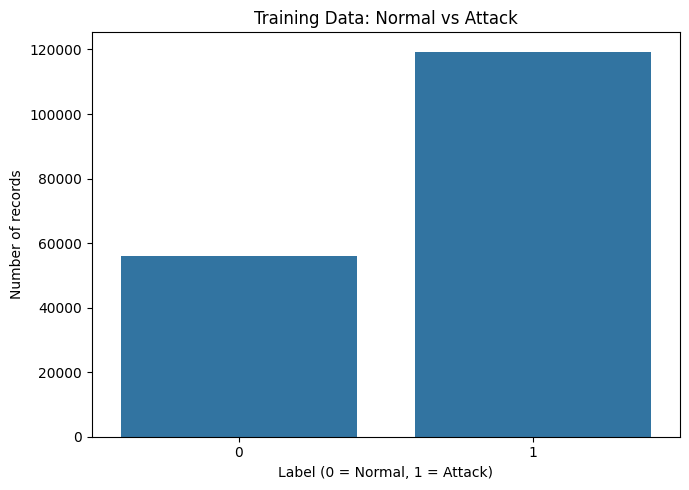

In [16]:
plt.figure(figsize=(7,5))
sns.countplot(x=y_train)
plt.title("Training Data: Normal vs Attack")
plt.xlabel("Label (0 = Normal, 1 = Attack)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.savefig(FIG / "class_distribution.png", dpi=200)
plt.show()


,count
attack_cat,
Normal,56000
Generic,40000
Exploits,33393
Fuzzers,18184
DoS,12264
Reconnaissance,10491
Analysis,2000
Backdoor,1746
Shellcode,1133


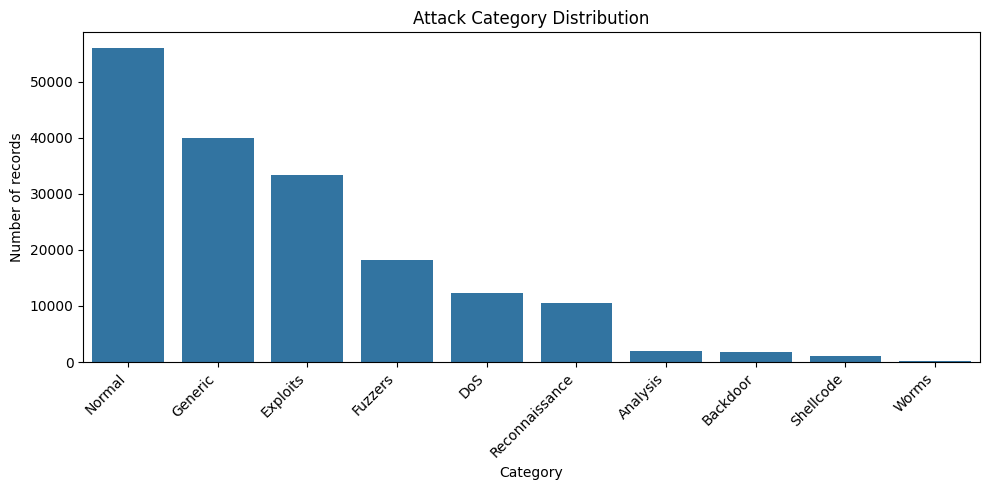

In [17]:
if "attack_cat" in train.columns:
    attack_counts = (
        train["attack_cat"].fillna("Normal").astype(str).str.strip()
        .replace({"": "Normal"}).value_counts()
    )
    display(attack_counts.to_frame("count"))

    plt.figure(figsize=(10,5))
    sns.barplot(x=attack_counts.index, y=attack_counts.values)
    plt.xticks(rotation=45, ha="right")
    plt.title("Attack Category Distribution")
    plt.xlabel("Category")
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.savefig(FIG / "attack_category_distribution.png", dpi=200)
    plt.show()


 Random Forest Model Training 




In [18]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols)
])

rf = RandomForestClassifier(
    n_estimators=250,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced_subsample"
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", rf)
])

pipeline.fit(X_train, y_train)
print("Training complete.")


Training complete.


Accuracy f1 score etc


In [19]:
pred = pipeline.predict(X_test)

accuracy = accuracy_score(y_test, pred)
precision = precision_score(y_test, pred, pos_label=1, zero_division=0)
recall = recall_score(y_test, pred, pos_label=1, zero_division=0)
f1 = f1_score(y_test, pred, pos_label=1, zero_division=0)

print(f"Accuracy        : {accuracy:.4f}")
print(f"Attack Precision: {precision:.4f}")
print(f"Attack Recall   : {recall:.4f}")
print(f"Attack F1-score : {f1:.4f}")

print("\nDetailed classification report:")
print(classification_report(
    y_test, pred, target_names=["Normal", "Attack"], zero_division=0
))


Accuracy        : 0.8707
Attack Precision: 0.8163
Attack Recall   : 0.9874
Attack F1-score : 0.8937

Detailed classification report:
              precision    recall  f1-score   support

      Normal       0.98      0.73      0.83     37000
      Attack       0.82      0.99      0.89     45332

    accuracy                           0.87     82332
   macro avg       0.90      0.86      0.86     82332
weighted avg       0.89      0.87      0.87     82332



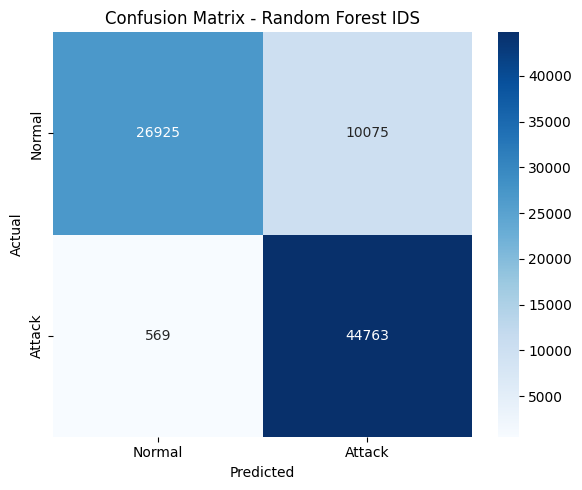

Confusion matrix:
[[26925 10075]
 [  569 44763]]


In [20]:
cm = confusion_matrix(y_test, pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Normal", "Attack"],
    yticklabels=["Normal", "Attack"]
)
plt.title("Confusion Matrix - Random Forest IDS")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(FIG / "confusion_matrix.png", dpi=200)
plt.show()

print("Confusion matrix:")
print(cm)


In [21]:
# Save model and metrics
joblib.dump(pipeline, MODEL_DIR / "unsw_nb15_random_forest.joblib")

metrics = {
    "accuracy": float(accuracy),
    "precision_attack": float(precision),
    "recall_attack": float(recall),
    "f1_attack": float(f1)
}
with open(RESULTS / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

pd.DataFrame(
    classification_report(
        y_test, pred, target_names=["Normal", "Attack"],
        output_dict=True, zero_division=0
    )
).transpose().to_csv(RESULTS / "classification_report.csv")

print("Saved model and evaluation files.")


Saved model and evaluation files.


Showing the top feature which feature is how important for prediction


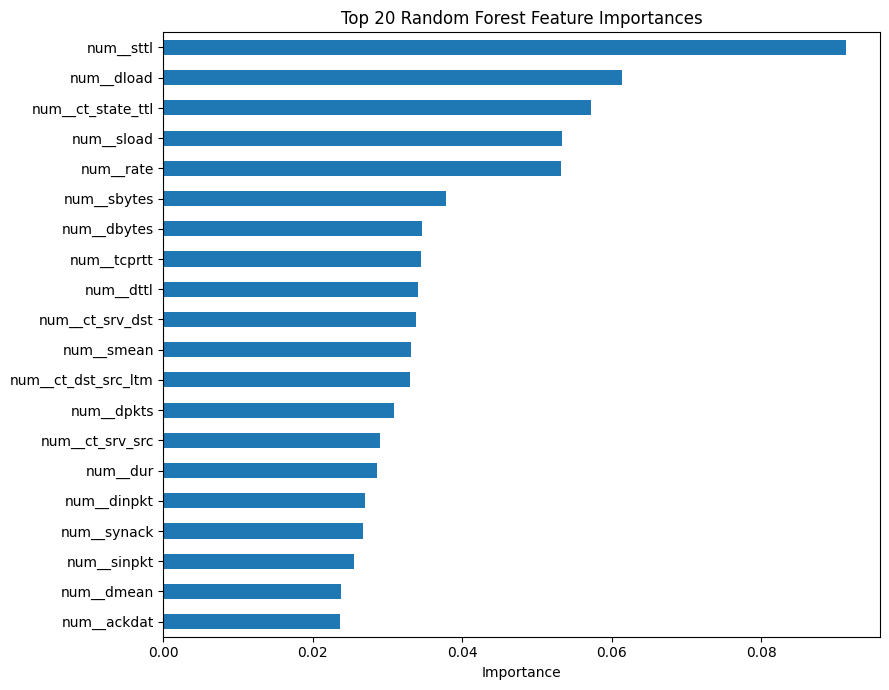

In [22]:
# Top feature importances
try:
    feature_names = pipeline.named_steps["preprocessor"].get_feature_names_out()
    importances = pipeline.named_steps["classifier"].feature_importances_
    fi = (
        pd.Series(importances, index=feature_names)
        .sort_values(ascending=False)
        .head(20)
        .sort_values()
    )
    plt.figure(figsize=(9,7))
    fi.plot(kind="barh")
    plt.title("Top 20 Random Forest Feature Importances")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.savefig(FIG / "feature_importance.png", dpi=200)
    plt.show()
except Exception as exc:
    print("Feature importance could not be generated:", exc)
